In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

In [3]:
DATA_DIR = Path("../data/raw")
IMG_DIR = DATA_DIR / "images"

In [5]:
df = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")
print(df.shape)
df.head(10)

(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear
5,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear
6,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face
7,HAM_0002761,ISIC_0029068,bkl,histo,60.0,male,face
8,HAM_0005132,ISIC_0025837,bkl,histo,70.0,female,back
9,HAM_0005132,ISIC_0025209,bkl,histo,70.0,female,back


dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


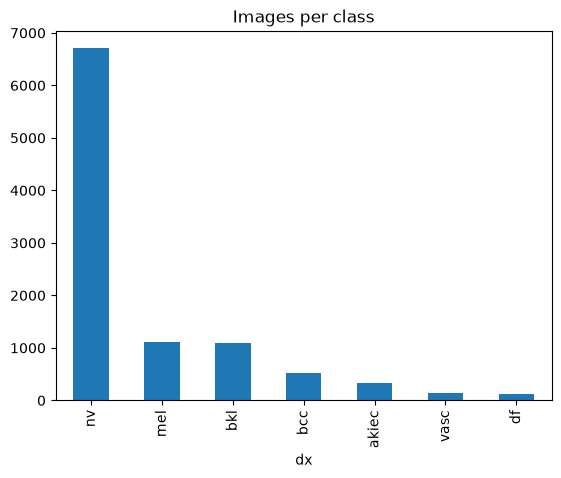

In [7]:

counts = df["dx"].value_counts()
print(counts)
counts.plot(kind="bar", title="Images per class")
plt.show()

In [8]:
print("Total images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())

Total images: 10015
Unique lesions: 7470


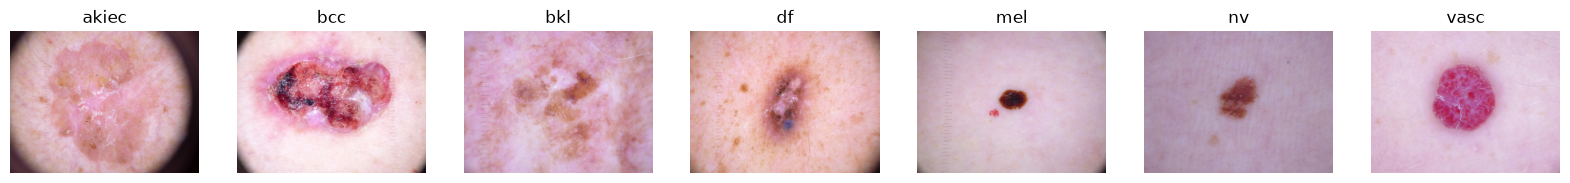

In [11]:
fig, axes = plt.subplots(1, 7, figsize=(20, 4))
for ax, cls in zip(axes, sorted(df["dx"].unique())):
    img_id = df[df["dx"] == cls]["image_id"].iloc[0]
    ax.imshow(Image.open(IMG_DIR / f"{img_id}.jpg"))
    ax.set_title(cls)
    ax.axis("off")
plt.show()

In [12]:
sample = Image.open(IMG_DIR / f"{df['image_id'].iloc[0]}.jpg")
print("Image size:", sample.size)
print(df.isnull().sum())

Image size: (600, 450)
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64
